# 06. Direct Complex MP-PCA — 3-Core Parallel

`02_Add_noise_Open_QSM_FULL_VOLUME_REVISED.ipynb`에서 생성한
**5-echo noisy complex GRE**를 complex-valued 4D 데이터 그대로 사용하여
Direct Complex MP-PCA denoising을 수행한다.

이번 버전은 서버 CPU 3개를 활용하기 위해
**Noise 10%, 30%, 50%를 각각 독립 프로세스에서 동시에 처리**한다.

```text
Process 1 → Noise 10% Direct Complex MP-PCA
Process 2 → Noise 30% Direct Complex MP-PCA
Process 3 → Noise 50% Direct Complex MP-PCA
```

Direct Complex 방식은 Real/Imaginary를 따로 분리해 PCA하거나
10개 real-valued feature로 결합하지 않는다.

입력 구조:

```text
(X, Y, Z, 5) complex
```

각 local patch에서 complex covariance는 Hermitian 형태로 계산된다.

```text
C = Xᴴ X / n
```

실험 원칙:

- 입력: `(X, Y, Z, 5)` complex64
- Echoes = 5
- Patch radius = 3 → `7 × 7 × 7`
- Patch voxels = 343
- Features = 5 complex echoes
- **Brain mask는 denoising에 사용하지 않음**
- **전체 volume denoising**
- Brain mask는 최종 평가 ROI용으로만 저장
- complex 입력을 직접 지원하는 `localpca.py`의 `mppca()` 사용


In [1]:
import os
import time
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from pathlib import Path
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed


/home/std-202100776/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-z29iadix because there was an issue with the default path (/home/std-202100776/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


### 환경설정

입력 noisy data:

`./data/noisy_data/`

- `qsm_siemens_monopolar_noisy_10.npz`
- `qsm_siemens_monopolar_noisy_30.npz`
- `qsm_siemens_monopolar_noisy_50.npz`

출력:

`./data/denoised/direct_complex/`

서버 실행 시 이 notebook과 함께 complex 입력을 지원하는
`localpca.py`가 `~/workspace`에서 import 가능해야 한다.

3-core 병렬화는 noise level 단위로 수행한다.
각 worker가 자기 `.npz` 파일을 직접 읽고 Direct Complex MP-PCA를 수행한 뒤
자기 결과 `.mat` 파일을 직접 저장한다.


In [2]:
NOISE_LEVELS = [10, 30, 50]

PATCH_R = 3
N_ECHO = 5
N_WORKERS = 3

NOISY_DIR = Path("./data/noisy_data").resolve()
OUT_DIR = Path("./data/denoised/direct_complex").resolve()

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Noisy directory :", NOISY_DIR)
print("Output directory:", OUT_DIR)
print("Echoes          :", N_ECHO)
print("Patch radius    :", PATCH_R)
print("Parallel workers:", N_WORKERS)
print(
    "Patch size      :",
    f"{2 * PATCH_R + 1} x {2 * PATCH_R + 1} x {2 * PATCH_R + 1}"
)


Noisy directory : /home/std-202100776/workspace/data/noisy_data
Output directory: /home/std-202100776/workspace/data/denoised/direct_complex
Echoes          : 5
Patch radius    : 3
Parallel workers: 3
Patch size      : 7 x 7 x 7


### 1. 입력 파일 확인

부모 프로세스에서는 세 noise level의 입력 파일 존재 여부만 확인한다.

각 worker가 자기 noise level의 `.npz`를 직접 읽도록 하여
큰 4D complex 배열을 프로세스 간에 전달하지 않는다.


In [3]:
input_paths = {}

for noise_level in NOISE_LEVELS:
    noisy_path = (
        NOISY_DIR /
        f"qsm_siemens_monopolar_noisy_{noise_level}.npz"
    )

    if not noisy_path.exists():
        raise FileNotFoundError(
            f"Noise 파일을 찾을 수 없습니다: {noisy_path}\n"
            "먼저 02_Add_noise_Open_QSM_FULL_VOLUME_REVISED.ipynb를 실행하세요."
        )

    input_paths[noise_level] = noisy_path
    print(f"{noise_level}% 입력 확인 -> {noisy_path}")

print("\n모든 입력 파일 확인 완료")


10% 입력 확인 -> /home/std-202100776/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_10.npz
30% 입력 확인 -> /home/std-202100776/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_30.npz
50% 입력 확인 -> /home/std-202100776/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_50.npz

모든 입력 파일 확인 완료


### 2. Direct Complex MP-PCA worker

각 worker는 하나의 noise level 전체를 담당한다.

처리 순서:

1. noisy complex GRE `(X,Y,Z,5)` 로드
2. complex-valued 데이터 그대로 MP-PCA에 입력
3. 전체 volume denoising
4. 결과 `.mat` 저장

Direct Complex에서는 입력을 Real/Imaginary로 분리하여 따로 denoising하지 않는다.

`mask_brain`은 결과 파일에 저장하지만 **MP-PCA 함수에는 전달하지 않는다.**


In [4]:
def run_direct_complex_worker(
    noise_level,
    noisy_path_str,
    out_dir_str,
    patch_r,
    n_echo
):
    import os
    import time
    import numpy as np
    import scipy.io as sio
    from pathlib import Path

    # complex-valued input을 직접 지원하는 custom localpca
    from localpca import mppca

    start_time = time.time()

    noisy_path = Path(noisy_path_str)
    out_dir = Path(out_dir_str)
    out_dir.mkdir(parents=True, exist_ok=True)

    print(
        f"[PID {os.getpid()}] START | Noise {noise_level}% | "
        f"file={noisy_path.name}",
        flush=True
    )

    data = np.load(noisy_path, allow_pickle=False)

    noisy_complex = data["noisy_complex"].astype(np.complex64)
    mask = data["mask_brain"].astype(bool)

    if noisy_complex.ndim != 4:
        raise ValueError(
            f"{noise_level}% noisy_complex는 4D여야 합니다. "
            f"현재 shape={noisy_complex.shape}"
        )

    if noisy_complex.shape[-1] != n_echo:
        raise ValueError(
            f"{noise_level}% 데이터는 {n_echo} echoes를 예상합니다. "
            f"실제={noisy_complex.shape[-1]}"
        )

    if mask.shape != noisy_complex.shape[:3]:
        raise ValueError(
            f"{noise_level}% mask shape {mask.shape} != "
            f"spatial shape {noisy_complex.shape[:3]}"
        )

    noise_ratio = float(data["noise_ratio"])
    sigma = float(data["sigma"])
    seed = int(data["seed"])
    overall_mean = float(data["overall_mean"])

    echo_times = (
        data["echo_times"].astype(np.float64)
        if "echo_times" in data.files
        else np.full(n_echo, np.nan, dtype=np.float64)
    )

    field_strength = (
        float(data["field_strength"])
        if "field_strength" in data.files
        else np.nan
    )

    print(
        f"[PID {os.getpid()}] DIRECT COMPLEX MP-PCA | "
        f"Noise {noise_level}% | shape={noisy_complex.shape} | "
        f"dtype={noisy_complex.dtype} | patch_radius={patch_r} | "
        "mask=NOT_USED | ROI=FULL_VOLUME",
        flush=True
    )

    # 핵심: complex-valued 5-echo 데이터를 그대로 입력
    deno_complex = mppca(
        noisy_complex,
        patch_radius=patch_r
    ).astype(np.complex64)

    if deno_complex.shape != noisy_complex.shape:
        raise ValueError(
            f"{noise_level}% denoised shape {deno_complex.shape} "
            f"!= input {noisy_complex.shape}"
        )

    if not np.iscomplexobj(deno_complex):
        raise TypeError(
            f"{noise_level}% Direct Complex 결과가 complex가 아닙니다."
        )

    output_path = (
        out_dir /
        f"denoised_direct_complex_{noise_level}_r{patch_r}.mat"
    )

    save_data = {
        "deno_complex": deno_complex,
        "mask_brain": mask.astype(np.uint8),
        "noise_level": np.int32(noise_level),
        "noise_ratio": np.float32(noise_ratio),
        "sigma": np.float32(sigma),
        "seed": np.int32(seed),
        "overall_mean": np.float32(overall_mean),
        "patch_radius": np.int32(patch_r),
        "n_echo": np.int32(n_echo),
        "echo_times": np.asarray(echo_times, dtype=np.float64),
        "field_strength": np.float32(field_strength),
        "denoise_region": "full_volume",
        "mask_usage": "evaluation_only",
        "parallel_workers": np.int32(3),
        "method": "direct_complex_mppca",
    }

    sio.savemat(
        output_path,
        save_data,
        do_compression=True
    )

    elapsed = time.time() - start_time

    print(
        f"[PID {os.getpid()}] DONE | Noise {noise_level}% | "
        f"{elapsed / 60:.2f} min | {output_path.name}",
        flush=True
    )

    return {
        "noise_level": int(noise_level),
        "output_path": str(output_path),
        "elapsed_sec": float(elapsed),
        "pid": int(os.getpid()),
    }


### 3. 10% / 30% / 50%를 3코어 동시 실행

Linux 서버에서 `fork` multiprocessing context를 사용한다.

```text
Worker 1 → Noise 10% Direct Complex MP-PCA
Worker 2 → Noise 30% Direct Complex MP-PCA
Worker 3 → Noise 50% Direct Complex MP-PCA
```

서버 제출 조건:

- `-c 3`
- `OMP_NUM_THREADS=1`
- `OPENBLAS_NUM_THREADS=1`
- `MKL_NUM_THREADS=1`

따라서 3개 worker가 각각 한 CPU core를 중심으로 사용한다.


In [5]:
parallel_start = time.time()
worker_results = {}

ctx = mp.get_context("fork")

print("=" * 70)
print("3-Core Parallel Direct Complex MP-PCA 시작")
print(f"Noise levels : {NOISE_LEVELS}")
print(f"Workers      : {N_WORKERS}")
print(f"Echoes       : {N_ECHO}")
print(f"Patch radius : {PATCH_R}")
print("=" * 70)

with ProcessPoolExecutor(
    max_workers=N_WORKERS,
    mp_context=ctx
) as executor:

    future_to_level = {
        executor.submit(
            run_direct_complex_worker,
            noise_level,
            str(input_paths[noise_level]),
            str(OUT_DIR),
            PATCH_R,
            N_ECHO
        ): noise_level
        for noise_level in NOISE_LEVELS
    }

    for future in as_completed(future_to_level):
        noise_level = future_to_level[future]

        try:
            result = future.result()
            worker_results[noise_level] = result

            print(
                f"MAIN: {noise_level}% 완료 | "
                f"PID={result['pid']} | "
                f"{result['elapsed_sec'] / 60:.2f} min"
            )

        except Exception as e:
            print(
                f"MAIN: {noise_level}% FAILED -> {repr(e)}"
            )
            raise

parallel_elapsed = time.time() - parallel_start

print("\n" + "=" * 70)
print("모든 noise level Direct Complex MP-PCA 병렬 처리 완료")
print(f"전체 wall time: {parallel_elapsed / 60:.2f} min")
print("=" * 70)

for noise_level in sorted(worker_results):
    print(worker_results[noise_level])


3-Core Parallel Direct Complex MP-PCA 시작
Noise levels : [10, 30, 50]
Workers      : 3
Echoes       : 5
Patch radius : 3


[PID 91] START | Noise 30% | file=qsm_siemens_monopolar_noisy_30.npz

[PID 92] START | Noise 50% | file=qsm_siemens_monopolar_noisy_50.npz

[PID 90] START | Noise 10% | file=qsm_siemens_monopolar_noisy_10.npz

[PID 92] DIRECT COMPLEX MP-PCA | Noise 50% | shape=(176, 256, 144, 5) | dtype=complex64 | patch_radius=3 | mask=NOT_USED | ROI=FULL_VOLUME

[PID 91] DIRECT COMPLEX MP-PCA | Noise 30% | shape=(176, 256, 144, 5) | dtype=complex64 | patch_radius=3 | mask=NOT_USED | ROI=FULL_VOLUME

... (3 outputs left out)

[PID 91] DONE | Noise 30% | 14.36 min | denoised_direct_complex_30_r3.mat

MAIN: 30% 완료 | PID=91 | 14.36 min


[PID 90] DONE | Noise 10% | 14.70 min | denoised_direct_complex_10_r3.mat

MAIN: 10% 완료 | PID=90 | 14.70 min

모든 noise level Direct Complex MP-PCA 병렬 처리 완료
전체 wall time: 14.71 min
{'noise_level': 10, 'output_path': '/home/std-202100776/workspace/data/denoised/direct_complex/denoised_direct_complex_10_r3.mat', 'elapsed_sec': 881.7222092151642, 'pid': 90}
{'noise_level': 30, 'output_path': '/home/std-202100776/workspace/data/denoised/direct_complex/denoised_direct_complex_30_r3.mat', 'elapsed_sec': 861.6153249740601, 'pid': 91}
{'noise_level': 50, 'output_path': '/home/std-202100776/workspace/data/denoised/direct_complex/denoised_direct_complex_50_r3.mat', 'elapsed_sec': 861.349142074585, 'pid': 92}


### 4. 저장 결과 확인

각 worker가 자기 noise level의 최종 complex 결과를 직접 저장한다.

출력 파일:

- `denoised_direct_complex_10_r3.mat`
- `denoised_direct_complex_30_r3.mat`
- `denoised_direct_complex_50_r3.mat`

결과는 `(X,Y,Z,5)` complex-valued 데이터로 유지된다.


In [6]:
output_paths = {}

for noise_level in NOISE_LEVELS:
    output_path = (
        OUT_DIR /
        f"denoised_direct_complex_{noise_level}_r{PATCH_R}.mat"
    )

    if not output_path.exists():
        raise FileNotFoundError(
            f"{noise_level}% 결과 파일이 생성되지 않았습니다: {output_path}"
        )

    output_paths[noise_level] = output_path

    size_mb = output_path.stat().st_size / (1024 ** 2)

    print(
        f"{noise_level}% 결과 확인 | "
        f"{output_path.name} | {size_mb:.1f} MB"
    )


10% 결과 확인 | denoised_direct_complex_10_r3.mat | 231.9 MB
30% 결과 확인 | denoised_direct_complex_30_r3.mat | 231.5 MB
50% 결과 확인 | denoised_direct_complex_50_r3.mat | 231.6 MB


### 5. 결과 시각화

Clean reference는 이 notebook에서 직접 사용하지 않는다.

noise level 하나씩 입력과 denoised 결과를 읽어 다음을 확인한다.

- Noisy Magnitude
- Denoised Magnitude
- Removed = `Noisy - Denoised`

`Removed`는 최종 error map이 아니라
Direct Complex MP-PCA가 noisy magnitude에서 제거한 성분을 보기 위한 시각화이다.

최종 PSNR / SSIM / NRMSE / HFEN은 별도 평가 단계에서
clean reference와 `mask_brain`을 사용한다.


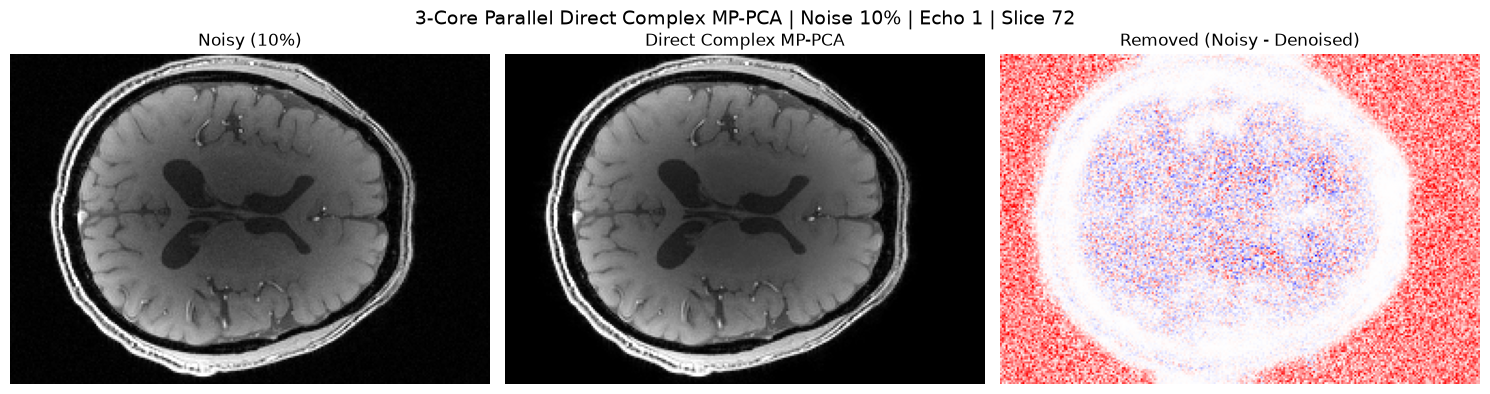

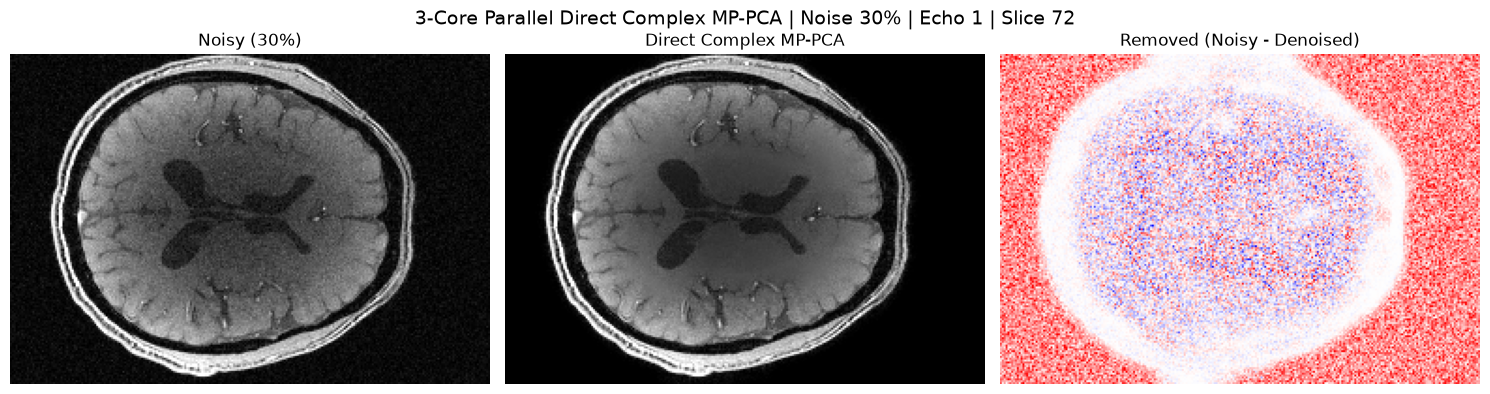

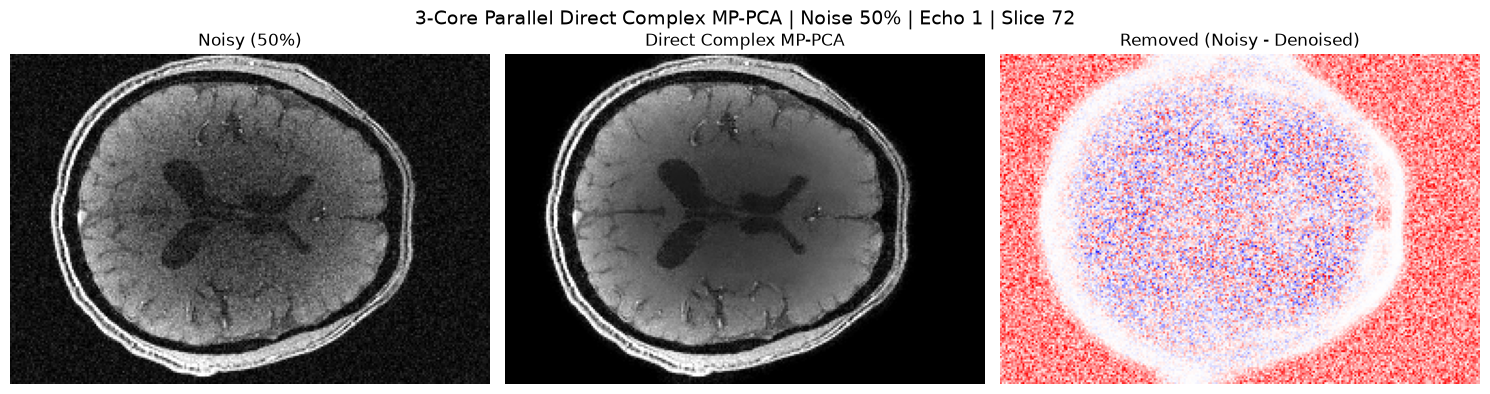

In [7]:
echo_idx = 0

for noise_level in NOISE_LEVELS:
    noisy_npz = np.load(
        input_paths[noise_level],
        allow_pickle=False
    )
    noisy_complex = noisy_npz["noisy_complex"].astype(np.complex64)

    mat = sio.loadmat(output_paths[noise_level])
    deno_complex = mat["deno_complex"].astype(np.complex64)

    if deno_complex.shape != noisy_complex.shape:
        raise ValueError(
            f"{noise_level}% visualization shape mismatch: "
            f"{deno_complex.shape} != {noisy_complex.shape}"
        )

    noisy_mag = np.abs(noisy_complex).astype(np.float32)
    deno_mag = np.abs(deno_complex).astype(np.float32)

    slice_idx = noisy_mag.shape[2] // 2

    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    deno_2d = deno_mag[:, :, slice_idx, echo_idx]
    removed_2d = noisy_2d - deno_2d

    vmin, vmax = np.percentile(noisy_2d, (1, 99))

    dv = float(np.percentile(np.abs(removed_2d), 99))
    dv = max(dv, 1e-8)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    ax[0].imshow(
        noisy_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[0].set_title(f"Noisy ({noise_level}%)")

    ax[1].imshow(
        deno_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[1].set_title("Direct Complex MP-PCA")

    ax[2].imshow(
        removed_2d,
        cmap="bwr",
        vmin=-dv,
        vmax=dv
    )
    ax[2].set_title("Removed (Noisy - Denoised)")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f"3-Core Parallel Direct Complex MP-PCA | "
        f"Noise {noise_level}% | Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    del noisy_complex, deno_complex, noisy_mag, deno_mag, mat
